# Caja negra

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display, Image
import time

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3})
AZUL, NARANJA, GRIS = '#2a78d6', '#eb6834', '#8a8984'

## Parámetros

In [ ]:
SIMULAR = False      # True: caja simulada (sin osciloscopio)
DIRECCION = 'visa://155.210.95.139/USB0::0x0957::0x179B::MY51135621::INSTR'
F_MAX = 500e3        # límite de los profesores: nunca se pasa de aquí
F_MAX_AJUSTE = 500e3 # puntos que se usan en los ajustes (bajarlo si el amplificador limita a alta frecuencia)

AMPLITUD = 1.0       # V pico a pico del generador
ESPERA = 0.5         # s de espera después de cambiar algo en el osciloscopio

# Barrido amplio
F_INICIO = 2e3       # Hz
F_FIN = 500e3        # Hz
PUNTOS = 60

# Zoom en la frecuencia de corte
PUNTOS_ZOOM = 30
REPETICIONES = 5
ANCHO_ZOOM = 1.6     # el zoom va de fc/1.6 a fc*1.6

# Barrido en amplitud
F_AMPLITUD = 100e3                      # frecuencia de la banda pasante
AMPLITUDES = np.linspace(0.2, 5, 13)    # V pico a pico (el generador da como mucho 5 Vpp)

**Modelo de paso alto de 2º orden** ($x = f/f_0$):

$$|H| = \frac{K\,x^2}{\sqrt{(1-x^2)^2 + (x/Q)^2}}, \qquad \varphi = 180^\circ - \arctan\!\frac{x/Q}{1-x^2}$$

- $K$: ganancia en la banda pasante (frecuencias altas).
- $f_0$: frecuencia propia. Ahí la fase vale **exactamente 90°**.
- $Q$: factor de calidad. Si $Q = 0.707$, $f_c = f_0$; si $Q < 0.707$, $f_c > f_0$.
- Frecuencia de corte (−3 dB, ganancia $K/\sqrt2$): $f_c = f_0 \Big/ \sqrt{a + \sqrt{a^2+1}}$, con $a = 1 - \frac{1}{2Q^2}$.

In [4]:
def caja_simulada(f, vpp):
    """Caja falsa para probar el código: paso alto con K = 1.9, f0 = 17 kHz, Q = 0.55.
    Satura a 8 Vpp (valor inventado: la caja real puede saturar a otra tensión o no saturar)."""
    x = f/17e3
    H = -1.9*x**2/(1 - x**2 + 1j*x/0.55)
    vin = vpp*(1 + 0.002*np.random.randn())
    vout = min(abs(H)*vpp, 8.0)*(1 + 0.005*np.random.randn())
    fase = np.degrees(np.angle(H)) + 0.5*np.random.randn()
    return vin, vout, fase % 360

def poner_frecuencia(f):
    if f > F_MAX:
        raise ValueError(f'{f:.0f} Hz supera el límite de {F_MAX:.0f} Hz')
    if not SIMULAR:
        instrumento.write('wgen:freq ' + str(f))
        instrumento.write('tim:rang ' + str(5/f))      # 5 periodos en pantalla
        time.sleep(ESPERA)

def poner_amplitud(vpp):
    global amplitud_actual
    amplitud_actual = vpp
    if not SIMULAR:
        instrumento.write('wgen:volt ' + str(vpp))
        instrumento.write('chan1:rang ' + str(1.6*vpp))
        time.sleep(ESPERA)

def leer(orden):
    v = float(instrumento.query(orden))
    return np.nan if abs(v) > 1e30 else v               # 9.9E37 = medida no válida

def medir(f):
    """Vin y Vout (V pico a pico) y fase de la salida respecto a la entrada (grados)."""
    global rango2
    poner_frecuencia(f)
    if SIMULAR:
        return caja_simulada(f, amplitud_actual)
    for intento in range(5):                            # ajustar la escala del canal 2
        vout = leer('meas:vamp? chan2')
        if np.isnan(vout):
            nuevo = 3*rango2                            # la señal se sale de la pantalla
        elif vout > 0.8*rango2 or vout < 0.3*rango2:
            nuevo = max(1.6*vout, 0.016)                # que ocupe ~60 % de la pantalla
        else:
            break
        nuevo = min(nuevo, 40)
        if abs(nuevo - rango2) < 0.05*rango2:
            break
        rango2 = nuevo
        instrumento.write('chan2:rang ' + str(rango2))
        time.sleep(ESPERA)
    vin = leer('meas:vamp? chan1')
    vout = leer('meas:vamp? chan2')
    fase = leer('meas:phas? chan2,chan1')
    if fase < -90:
        fase += 360                                     # en un paso alto la fase va de 180° a 0°
    return vin, vout, fase

def barrido(frecuencias):
    datos = np.array([medir(f) for f in frecuencias])
    return datos[:, 0], datos[:, 1], datos[:, 2]

def cruce(f, y, nivel, n=12):
    """Frecuencia a la que y llega a 'nivel': parábola (frente a log f) por los n puntos que rodean el cruce."""
    ok = np.isfinite(y)
    x, y = np.log10(f[ok]), y[ok]
    if not (y.min() < nivel < y.max()):
        return np.nan                                   # y no llega a 'nivel' en este rango
    j = np.argmin(np.abs(y - nivel))                    # punto más cercano al nivel
    i = np.argsort(np.abs(x - x[j]))[:n]                # los n puntos más cercanos a él en frecuencia
    raices = np.roots(np.polyfit(x[i], y[i], 2) - np.array([0, 0, nivel]))
    raices = raices[np.isreal(raices)].real
    if len(raices) == 0:
        return np.nan
    return 10**raices[np.argmin(np.abs(raices - x[j]))]

def ganancia_modelo(f, K, f0, Q):
    x = f/f0
    return K*x**2/np.sqrt((1 - x**2)**2 + (x/Q)**2)

def fase_modelo(f, f0, Q):
    x = f/f0
    return 180 - np.degrees(np.arctan2(x/Q, 1 - x**2))

def fc_modelo(f0, Q):
    a = 1 - 1/(2*Q**2)
    return f0/np.sqrt(a + np.sqrt(a**2 + 1))

## 1. Conexión con el osciloscopio

In [14]:
if SIMULAR:
    print('Modo simulación: no se usa el osciloscopio')
else:
    import pyvisa as visa
    resources = visa.ResourceManager()
    instrumento = resources.open_resource(DIRECCION)
    instrumento.timeout = 20000
    print(instrumento.query('*idn?'))
    instrumento.write('wgen:func sin')
    instrumento.write('wgen:volt:offs 0')
    instrumento.write('wgen:outp 1')
    instrumento.write('chan1:disp 1')
    instrumento.write('chan2:disp 1')
    instrumento.write('chan1:coup dc')
    instrumento.write('chan2:coup dc')
    instrumento.write('chan1:offs 0')
    instrumento.write('chan2:offs 0')
    instrumento.write('trig:edge:sour wgen')
    instrumento.write('acq:type aver')
    instrumento.write('acq:count 8')
    rango2 = 2.0
    instrumento.write('chan2:rang 2')

poner_amplitud(AMPLITUD)

AGILENT TECHNOLOGIES,DSO-X 2002A,MY51135621,01.10.2011031600



## 2. Barrido amplio en frecuencia

Barrido hecho en 73 s
Ganancia en la banda pasante: K = 1.9185 ± 0.0070  (5.66 dB)
Frecuencia de corte (-3 dB):  fc ≈ 22332 Hz
Fase = 90° en:                f0 ≈ 17169 Hz
Pendiente a baja frecuencia:  nan dB/década  (2º orden: +40)


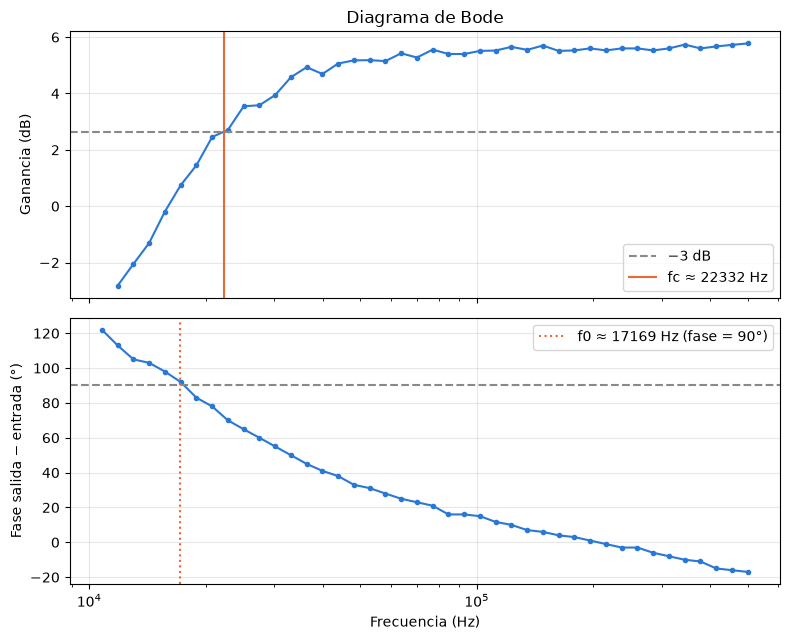

In [6]:
freq = np.logspace(np.log10(F_INICIO), np.log10(min(F_FIN, F_MAX)), PUNTOS)
t0 = time.time()
vin, vout, fase = barrido(freq)
print(f'Barrido hecho en {time.time() - t0:.0f} s')
G = vout/vin
G_dB = 20*np.log10(G)
np.savetxt('barrido_amplio.csv', np.column_stack([freq, vin, vout, fase]),
           delimiter=',', header='f_Hz,Vin_V,Vout_V,fase_grados', comments='')

ok = np.isfinite(G) & (G > 0) & (freq <= F_MAX_AJUSTE)
p_ini = [np.nanmax(G), freq[np.nanargmin(np.abs(fase - 90))], 0.7]
p_barrido, cov_barrido = curve_fit(ganancia_modelo, freq[ok], G[ok], p0=p_ini, sigma=G[ok])
K_ref, s_K_ref = p_barrido[0], np.sqrt(cov_barrido[0, 0])   # ganancia de la banda pasante (del ajuste)
nivel = K_ref/np.sqrt(2)                    # nivel de -3 dB
fc_est = cruce(freq, G, nivel)
f0_est = cruce(freq, fase, 90)            # en f0 la fase vale 90°
if not np.isfinite(fc_est):
    raise RuntimeError('No se encuentra la frecuencia de corte en el barrido: prueba a bajar F_INICIO')

bajas = (freq < fc_est/3) & np.isfinite(G_dB)    # sin los puntos que el osciloscopio no pudo medir
pendiente = np.polyfit(np.log10(freq[bajas]), G_dB[bajas], 1)[0] if bajas.sum() >= 3 else np.nan

print(f'Ganancia en la banda pasante: K = {K_ref:.4f} ± {s_K_ref:.4f}  ({20*np.log10(K_ref):.2f} dB)')
print(f'Frecuencia de corte (-3 dB):  fc ≈ {fc_est:.0f} Hz')
print(f'Fase = 90° en:                f0 ≈ {f0_est:.0f} Hz')
print(f'Pendiente a baja frecuencia:  {pendiente:.1f} dB/década  (2º orden: +40)')

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
a1.semilogx(freq, G_dB, 'o-', ms=3, color=AZUL)
a1.axhline(20*np.log10(nivel), color=GRIS, ls='--', label='−3 dB')
a1.axvline(fc_est, color=NARANJA, label=f'fc ≈ {fc_est:.0f} Hz')
a1.set_ylabel('Ganancia (dB)')
a1.set_title('Diagrama de Bode')
a1.legend()
a2.semilogx(freq, fase, 'o-', ms=3, color=AZUL)
a2.axhline(90, color=GRIS, ls='--')
a2.axvline(f0_est, color=NARANJA, ls=':', label=f'f0 ≈ {f0_est:.0f} Hz (fase = 90°)')
a2.set_ylabel('Fase salida − entrada (°)')
a2.set_xlabel('Frecuencia (Hz)')
a2.legend()
fig.tight_layout()
fig.savefig('bode.png', dpi=150)
plt.show()

## 3. Zoom en la frecuencia de corte

Barrido fino de $f_c/1.6$ a $1.6\,f_c$.


Repetición 1 de 5 hecha
Repetición 2 de 5 hecha
Repetición 3 de 5 hecha
Repetición 4 de 5 hecha
Repetición 5 de 5 hecha
fc de cada repetición: [21501.2 21823.3 21855.2 21673.7 21387.6] Hz
fc = 21648.2 ± 186.5 Hz   (repetibilidad ± 90.5 Hz, error de K ± 163.1 Hz)
f0 (fase = 90°) = 17159.7 ± 55.6 Hz


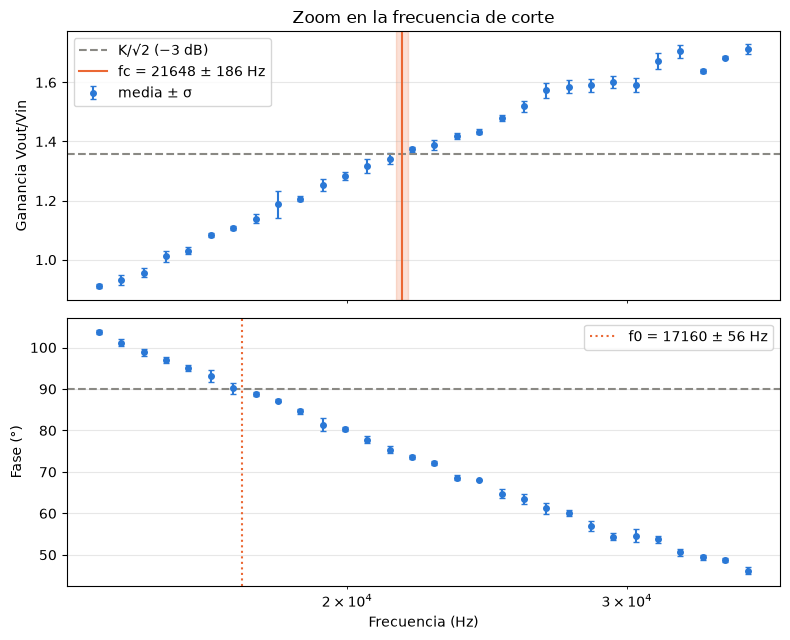

In [7]:
freq_z = np.logspace(np.log10(fc_est/ANCHO_ZOOM), np.log10(min(fc_est*ANCHO_ZOOM, F_MAX)), PUNTOS_ZOOM)
Gz = np.zeros((REPETICIONES, PUNTOS_ZOOM))
fase_z = np.zeros((REPETICIONES, PUNTOS_ZOOM))
for k in range(REPETICIONES):
    vin_z, vout_z, fase_z[k] = barrido(freq_z)
    Gz[k] = vout_z/vin_z
    print(f'Repetición {k + 1} de {REPETICIONES} hecha')
np.savetxt('zoom_fc.csv', np.column_stack([freq_z, Gz.T, fase_z.T]), delimiter=',',
           header='f_Hz,' + ','.join(f'G_{k+1}' for k in range(REPETICIONES))
                  + ',' + ','.join(f'fase_{k+1}' for k in range(REPETICIONES)), comments='')

fc_rep = np.array([cruce(freq_z, Gz[k], nivel) for k in range(REPETICIONES)])
f0_rep = np.array([cruce(freq_z, fase_z[k], 90) for k in range(REPETICIONES)])
G_media = Gz.mean(axis=0)
fc_z = np.mean(fc_rep)
s_fc_rep = np.std(fc_rep, ddof=1)/np.sqrt(REPETICIONES)                     # repetibilidad
d_nivel = s_K_ref/np.sqrt(2)
s_fc_K = abs(cruce(freq_z, G_media, nivel + d_nivel) - cruce(freq_z, G_media, nivel - d_nivel))/2   # error de K
s_fc = np.sqrt(s_fc_rep**2 + s_fc_K**2)
f0_z, s_f0 = np.mean(f0_rep), np.std(f0_rep, ddof=1)/np.sqrt(REPETICIONES)
print(f'fc de cada repetición: {np.round(fc_rep, 1)} Hz')
print(f'fc = {fc_z:.1f} ± {s_fc:.1f} Hz   (repetibilidad ± {s_fc_rep:.1f} Hz, error de K ± {s_fc_K:.1f} Hz)')
if np.isfinite(f0_z):
    print(f'f0 (fase = 90°) = {f0_z:.1f} ± {s_f0:.1f} Hz')
else:
    print('La fase no pasa por 90° dentro del zoom (f0 queda fuera): aumenta ANCHO_ZOOM si quieres medirla aquí.')

G_std = Gz.std(axis=0, ddof=1)
fase_media, fase_std = fase_z.mean(axis=0), fase_z.std(axis=0, ddof=1)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
a1.errorbar(freq_z, G_media, yerr=G_std, fmt='o', ms=4, capsize=2, color=AZUL, label='media ± σ')
a1.axhline(nivel, color=GRIS, ls='--', label='K/√2 (−3 dB)')
a1.axvline(fc_z, color=NARANJA, label=f'fc = {fc_z:.0f} ± {s_fc:.0f} Hz')
a1.axvspan(fc_z - s_fc, fc_z + s_fc, color=NARANJA, alpha=0.2)
a1.set_xscale('log')
a1.set_ylabel('Ganancia Vout/Vin')
a1.set_title('Zoom en la frecuencia de corte')
a1.legend()
a2.errorbar(freq_z, fase_media, yerr=fase_std, fmt='o', ms=4, capsize=2, color=AZUL)
a2.axhline(90, color=GRIS, ls='--')
if np.isfinite(f0_z):
    a2.axvline(f0_z, color=NARANJA, ls=':', label=f'f0 = {f0_z:.0f} ± {s_f0:.0f} Hz')
    a2.legend()
a2.set_ylabel('Fase (°)')
a2.set_xlabel('Frecuencia (Hz)')
fig.tight_layout()
fig.savefig('zoom_fc.png', dpi=150)
plt.show()

## 4. Ajuste al modelo de paso alto de 2º orden

K  = 1.9203 ± 0.0071   (5.67 dB)
f0 = 16989.3 ± 119.3 Hz
Q  = 0.5783 ± 0.0050
Error rms del ajuste: 1.82 %

fc según el modelo: 21563.8 ± 139.8 Hz   (zoom: 21648.2 ± 186.5 Hz)
f0 según el modelo: 16989.3 Hz   (fase = 90° en el zoom: 17159.7 ± 55.6 Hz)


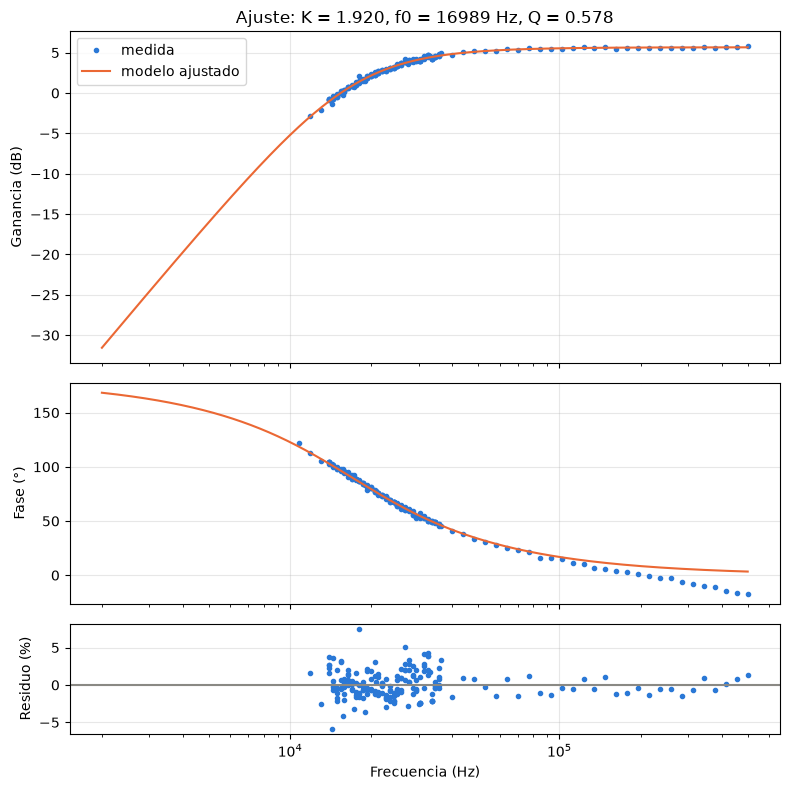

In [8]:
f_todo = np.concatenate([freq, np.tile(freq_z, REPETICIONES)])
G_todo = np.concatenate([G, Gz.ravel()])
fase_todo = np.concatenate([fase, fase_z.ravel()])
ok = np.isfinite(G_todo) & (G_todo > 0) & (f_todo <= F_MAX_AJUSTE)

p, cov = curve_fit(ganancia_modelo, f_todo[ok], G_todo[ok], p0=p_barrido, sigma=G_todo[ok])
K, f0, Q = p
sK, sf0, sQ = np.sqrt(np.diag(cov))
fc_mod = fc_modelo(f0, Q)
muestras = np.random.multivariate_normal(p, cov, 5000)        # error de fc: se repite el cálculo con
s_fc_mod = np.std(fc_modelo(muestras[:, 1], muestras[:, 2]))   # f0 y Q sorteados dentro de sus errores
error_rel = 100*np.sqrt(np.mean((G_todo[ok]/ganancia_modelo(f_todo[ok], *p) - 1)**2))

print(f'K  = {K:.4f} ± {sK:.4f}   ({20*np.log10(K):.2f} dB)')
print(f'f0 = {f0:.1f} ± {sf0:.1f} Hz')
print(f'Q  = {Q:.4f} ± {sQ:.4f}')
print(f'Error rms del ajuste: {error_rel:.2f} %')
print()
print(f'fc según el modelo: {fc_mod:.1f} ± {s_fc_mod:.1f} Hz   (zoom: {fc_z:.1f} ± {s_fc:.1f} Hz)')
print(f'f0 según el modelo: {f0:.1f} Hz   (fase = 90° en el zoom: {f0_z:.1f} ± {s_f0:.1f} Hz)')

fm = np.logspace(np.log10(F_INICIO), np.log10(min(F_FIN, F_MAX)), 500)
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(8, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2, 1]})
a1.semilogx(f_todo, 20*np.log10(G_todo), 'o', ms=3, color=AZUL, label='medida')
a1.semilogx(fm, 20*np.log10(ganancia_modelo(fm, *p)), color=NARANJA, label='modelo ajustado')
a1.set_ylabel('Ganancia (dB)')
a1.set_title(f'Ajuste: K = {K:.3f}, f0 = {f0:.0f} Hz, Q = {Q:.3f}')
a1.legend()
a2.semilogx(f_todo, fase_todo, 'o', ms=3, color=AZUL)
a2.semilogx(fm, fase_modelo(fm, f0, Q), color=NARANJA)
a2.set_ylabel('Fase (°)')
a3.semilogx(f_todo, 100*(G_todo/ganancia_modelo(f_todo, *p) - 1), 'o', ms=3, color=AZUL)
a3.axhline(0, color=GRIS)
a3.set_ylabel('Residuo (%)')
a3.set_xlabel('Frecuencia (Hz)')
fig.tight_layout()
fig.savefig('ajuste.png', dpi=150)
plt.show()

## 5. Barrido en amplitud

A una frecuencia de la banda pasante (`F_AMPLITUD`) se sube la amplitud del generador.

Generador 0.20 Vpp  ->  Vin = 0.201 V,  Vout = 0.394 V
Generador 0.60 Vpp  ->  Vin = 0.598 V,  Vout = 1.105 V
Generador 1.00 Vpp  ->  Vin = 0.982 V,  Vout = 1.862 V
Generador 1.40 Vpp  ->  Vin = 1.389 V,  Vout = 2.571 V
Generador 1.80 Vpp  ->  Vin = 1.790 V,  Vout = 3.292 V
Generador 2.20 Vpp  ->  Vin = 2.158 V,  Vout = 4.078 V
Generador 2.60 Vpp  ->  Vin = 2.609 V,  Vout = 4.769 V
Generador 3.00 Vpp  ->  Vin = 2.995 V,  Vout = 5.553 V
Generador 3.40 Vpp  ->  Vin = 3.398 V,  Vout = 6.285 V
Generador 3.80 Vpp  ->  Vin = 3.790 V,  Vout = 6.918 V
Generador 4.20 Vpp  ->  Vin = 4.173 V,  Vout = 7.310 V
Generador 4.60 Vpp  ->  Vin = 4.535 V,  Vout = 7.450 V
Generador 5.00 Vpp  ->  Vin = 4.905 V,  Vout = 7.450 V

Ganancia con señal pequeña a 100000 Hz: 1.870
Salida máxima medida: 7.45 Vpp
La ganancia cae más de un 3 % a partir de Vin ≈ 4.17 Vpp (Vout ≈ 7.31 Vpp): el circuito satura.


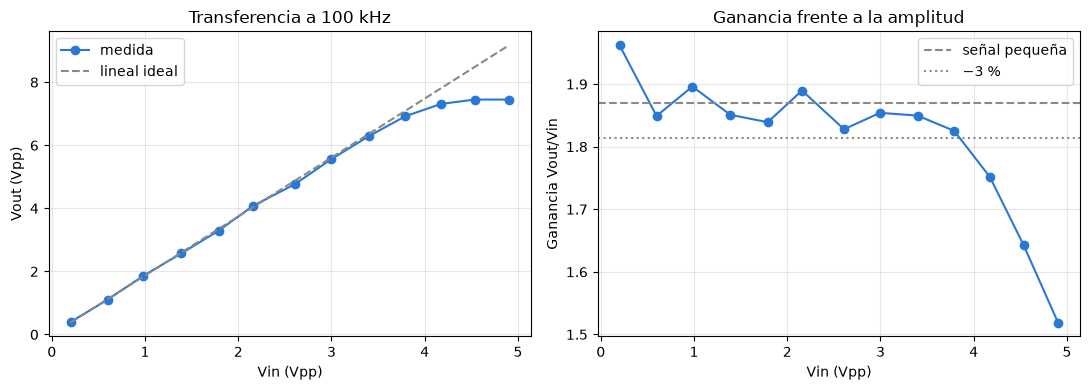

In [9]:
n = len(AMPLITUDES)
vin_a, vout_a = np.zeros(n), np.zeros(n)
for i, A in enumerate(AMPLITUDES):
    poner_amplitud(A)
    vin_a[i], vout_a[i], _ = medir(F_AMPLITUD)
    print(f'Generador {A:.2f} Vpp  ->  Vin = {vin_a[i]:.3f} V,  Vout = {vout_a[i]:.3f} V')
poner_amplitud(AMPLITUD)                         # volver a la amplitud normal
np.savetxt('barrido_amplitud.csv', np.column_stack([AMPLITUDES, vin_a, vout_a]),
           delimiter=',', header='A_generador_Vpp,Vin_V,Vout_V', comments='')

G_a = vout_a/vin_a
G0 = np.median(G_a[:n//2])                       # ganancia con señal pequeña (mediana de la primera mitad)
debajo = G_a < 0.97*G0                           # puntos más de un 3 % por debajo
satura = [i for i in range(n) if debajo[i:].all()]   # desde aquí, todos los siguientes están por debajo
print(f'\nGanancia con señal pequeña a {F_AMPLITUD:.0f} Hz: {G0:.3f}')
print(f'Salida máxima medida: {vout_a.max():.2f} Vpp')
if len(satura) > 0:
    print(f'La ganancia cae más de un 3 % a partir de Vin ≈ {vin_a[satura[0]]:.2f} Vpp '
          f'(Vout ≈ {vout_a[satura[0]]:.2f} Vpp): el circuito satura.')
else:
    print(f'Lineal en todo el rango probado (hasta Vin = {vin_a.max():.2f} Vpp, Vout = {vout_a.max():.2f} Vpp).')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(vin_a, vout_a, 'o-', color=AZUL, label='medida')
a1.plot(vin_a, G0*vin_a, '--', color=GRIS, label='lineal ideal')
a1.set_xlabel('Vin (Vpp)')
a1.set_ylabel('Vout (Vpp)')
a1.set_title(f'Transferencia a {F_AMPLITUD/1e3:.0f} kHz')
a1.legend()
a2.plot(vin_a, G_a, 'o-', color=AZUL)
a2.axhline(G0, color=GRIS, ls='--', label='señal pequeña')
a2.axhline(0.97*G0, color=GRIS, ls=':', label='−3 %')
a2.legend()
a2.set_xlabel('Vin (Vpp)')
a2.set_ylabel('Ganancia Vout/Vin')
a2.set_title('Ganancia frente a la amplitud')
fig.tight_layout()
fig.savefig('barrido_amplitud.png', dpi=150)
plt.show()

Seno de 5.0 Vpp a 100 kHz:
  Vmax salida = +3.84 V,  Vmin salida = -3.71 V,  valor medio = -0.057 V


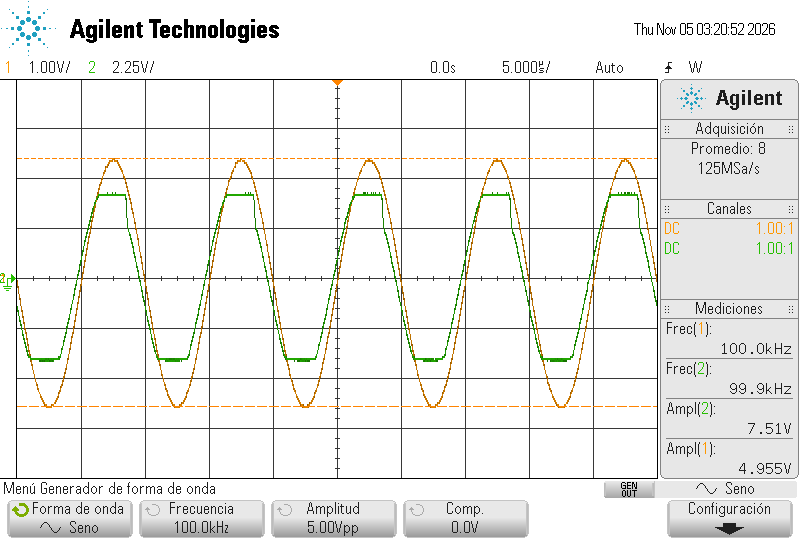

  Valor medio ≈ 0 V -> alimentación simétrica (±V)
  La salida se recorta: alimentación ≈ +3.8 V + margen  y  -3.7 V − margen (ver la tabla)


In [15]:
def captura_pantalla(nombre):
    """Guarda y muestra una captura de la pantalla del osciloscopio."""
    if SIMULAR:
        return
    try:
        datos = instrumento.query_binary_values(':disp:data? png, col', datatype='B', container=bytearray)
        with open(nombre, 'wb') as fh:
            fh.write(datos)
        display(Image(filename=nombre))
    except Exception as e:
        print('No se pudo hacer la captura de pantalla:', e)

def limites_salida(f):
    """Vmax, Vmin y valor medio de la salida (V)."""
    if SIMULAR:
        vin, vout, _ = caja_simulada(f, amplitud_actual)
        return vout/2, -vout/2, 0.0
    medir(f)                                    # ajusta la escala del canal 2
    return leer('meas:vmax? chan2'), leer('meas:vmin? chan2'), leer('meas:vav? chan2')

A_max = AMPLITUDES.max()
poner_amplitud(A_max)
vmax, vmin, vmed = limites_salida(F_AMPLITUD)
print(f'Seno de {A_max:.1f} Vpp a {F_AMPLITUD/1e3:.0f} kHz:')
print(f'  Vmax salida = {vmax:+.2f} V,  Vmin salida = {vmin:+.2f} V,  valor medio = {vmed:+.3f} V')
captura_pantalla('pantalla_seno.png')
poner_amplitud(AMPLITUD)

if abs(vmed) < 0.1:
    print('  Valor medio ≈ 0 V -> alimentación simétrica (±V)')
else:
    print(f'  La salida está centrada en {vmed:.2f} V -> probablemente una sola fuente de ≈ {2*vmed:.1f} V')
if len(satura) > 0:
    print(f'  La salida se recorta: alimentación ≈ {vmax:+.1f} V + margen  y  {vmin:+.1f} V − margen (ver la tabla)')
else:
    print(f'  La salida no se recorta: la alimentación positiva es mayor que {vmax:+.1f} V '
          f'y la negativa menor que {vmin:+.1f} V (más el margen del amplificador)')

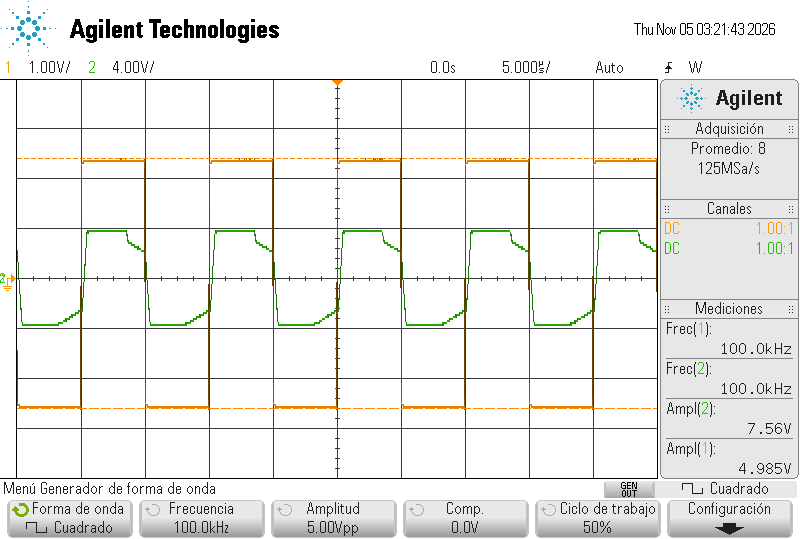

Onda cuadrada de 5.0 Vpp a 100000 Hz:
  picos de la salida: +3.87 V y -3.78 V   (sin saturar serían ≈ ±9.6 V)
  Los picos no llegan: mira en la captura si están planos (alimentación) o redondeados (slew rate).


In [17]:
# Prueba opcional con onda cuadrada (solo con el osciloscopio y con PROBAR_CUADRADA = True)
if PROBAR_CUADRADA and not SIMULAR:
    F_CUADRADA = 1e5                            # lenta: entre flancos la salida vuelve a 0
    instrumento.write('wgen:func squ')
    poner_amplitud(A_max)
    poner_frecuencia(F_CUADRADA)
    instrumento.write('chan2:rang 32')          # ±16 V en pantalla
    rango2 = 32
    time.sleep(3*ESPERA)
    vmax_c, vmin_c = leer('meas:vmax? chan2'), leer('meas:vmin? chan2')
    captura_pantalla('pantalla_cuadrada.png')
    instrumento.write('wgen:func sin')          # volver al seno
    poner_amplitud(AMPLITUD)
    print(f'Onda cuadrada de {A_max:.1f} Vpp a {F_CUADRADA:.0f} Hz:')
    print(f'  picos de la salida: {vmax_c:+.2f} V y {vmin_c:+.2f} V   (sin saturar serían ≈ ±{K*A_max:.1f} V)')
    if max(vmax_c, -vmin_c) < 0.9*K*A_max:
        print('  Los picos no llegan: mira en la captura si están planos (alimentación) o redondeados (slew rate).')
    else:
        print(f'  No satura: la alimentación es mayor que unos ±{K*A_max:.1f} V (más el margen del amplificador).')
else:
    print('Prueba con onda cuadrada desactivada (PROBAR_CUADRADA = False).')